# 06b · Cenários de simulação: Natal +40%, frota, docas, agendamento e slotting
Cada cenário muda **uma** coisa em relação à linha de base calibrada na 06a. Assim, o efeito de cada
decisão aparece isolado. No fim, um cenário combinado mostra o **plano para o pico**.

| Cenário | O que muda |
|---|---|
| S0 Base | operação atual (escala cheia, calibrada) |
| S1 Natal +40% | pedidos e caminhões de dezembro ×1,4 |
| S2 Retráteis −25% | frota do dia e da noite reduzida em 25% |
| S3 Docas frias +1 | 5 docas no resfriado e 5 no congelado (hoje 4 + 4) |
| S4 Agendamento distribuído | metade dos caminhões das 7h–12h passa para 13h–17h |
| S5 Slotting otimizado | faces de picking do modelo PuLP (Fase 5) |
| S6 Plano de pico | Natal +40% com S3 + S4 + S5 e reforço de equipe |

Indicadores: **fila do pedido** (dias), **% dos pedidos separados na noite prevista**, espera do
caminhão no pátio (p90) e dock-to-stock. Cada cenário leva ~1–2 min para rodar.

*EN summary: one-factor-at-a-time scenarios on the calibrated model plus a combined peak plan.*

In [1]:
import sys
sys.path.insert(0, "../src")
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flowsim as fs
from dcanalysis import save, savefig, log, register_saving, params, ROOT

NB = "06b"
PH6 = ROOT / "reports" / "phase6"
prm = fs.carregar_parametros()
slot = fs.carregar_slotting()
INI, FIM, MEDIR = "2025-09-24", "2026-02-01", "2025-10-01"
DEZ = ("2025-12-01", "2026-01-01")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
resultados, usos, recs = [], {}, {}

def rodar(nome, **kw):
    r, pal, ped, rec, uso = fs.rodar_cenario(nome, prm, slot, INI, FIM, MEDIR, **kw)
    resultados.append(r); usos[nome] = uso; recs[nome] = rec
    return r

In [2]:
rodar("S0 Base")
rodar("S1 Natal +40%", extra=(*DEZ, 1.4))
menos = {k: {z: math.ceil(v * 0.75) for z, v in prm[k].items()} for k in ("forklifts", "forklifts_night")}
rodar("S2 Retráteis -25%", forklifts=menos["forklifts"], forklifts_night=menos["forklifts_night"])
docas_frias = {**prm["docks"], "chilled": prm["docks"]["chilled"] + 1, "frozen": prm["docks"]["frozen"] + 1}
rodar("S3 Docas frias +1", docks=docas_frias)
AGENDA = (0.5, (7, 12), (13, 17))
rodar("S4 Agendamento distribuído", mover_chegadas=AGENDA)
rodar("S5 Slotting otimizado", dist_col="dist_otima")
pd.DataFrame(resultados).set_index("cenario").round(2).T

cenario,S0 Base,S1 Natal +40%,S2 Retráteis -25%,S3 Docas frias +1,S4 Agendamento distribuído,S5 Slotting otimizado
d2s_mediana_dry,50.40,55.46,61.60,50.40,44.80,50.40
espera_doca_p90_dry,53.46,76.28,53.46,53.46,27.86,53.46
d2s_mediana_chilled,149.91,183.28,149.92,108.55,134.45,149.91
espera_doca_p90_chilled,348.33,485.26,348.33,241.84,274.36,348.33
d2s_mediana_frozen,102.98,117.84,102.99,76.60,88.68,102.98
espera_doca_p90_frozen,169.40,215.99,169.40,104.73,147.81,169.40
fila_2025-10,0.26,0.26,0.69,0.26,0.26,0.26
na_noite_prevista_2025-10,0.99,0.99,0.55,0.99,0.99,0.99
fila_2025-11,0.33,0.33,1.68,0.33,0.33,0.29
na_noite_prevista_2025-11,0.93,0.93,0.07,0.93,0.93,0.97


## Plano de pico: quanto reforço de equipe o Natal +40% exige, com e sem slotting?
Com docas frias +1 (S3) e agendamento distribuído (S4) aplicados, aumentamos separadores e retráteis
da noite em degraus de 10% até que **≥ 90% dos pedidos de dezembro** saiam na noite prevista.
Fazemos isso duas vezes: com as faces atuais e com o slotting otimizado (S5). A diferença de equipe
é o valor do slotting no pico.
*Simplificação:* o reforço vale para a janela toda; na prática seriam temporários de novembro a janeiro.

In [3]:
def buscar_reforco(dist_col, rotulo, degraus=(1.3, 1.4, 1.5, 1.6, 1.7, 1.8)):
    linhas = []
    for reforco in degraus:
        pk = {z: math.ceil(v * reforco) for z, v in prm["pickers"].items()}
        fn = {z: math.ceil(v * reforco) for z, v in prm["forklifts_night"].items()}
        r, *_ = fs.rodar_cenario(f"{rotulo} {reforco:.1f}", prm, slot, INI, FIM, MEDIR, extra=(*DEZ, 1.4),
                                 docks=docas_frias, mover_chegadas=AGENDA, dist_col=dist_col,
                                 pickers=pk, forklifts_night=fn)
        r.update({"slotting": rotulo, "reforco": reforco,
                  "separadores": sum(pk.values()), "retrateis_noite": sum(fn.values())})
        linhas.append(r)
        print(f"{rotulo:16s} reforço {reforco:.1f}: {sum(pk.values())} separadores, {sum(fn.values())} "
              f"retráteis noite -> dez: fila {r['fila_2025-12']:.2f} d, na noite prevista "
              f"{r['na_noite_prevista_2025-12']:.0%}")
        if r["na_noite_prevista_2025-12"] >= 0.90:
            break
    return pd.DataFrame(linhas)

plano = buscar_reforco("dist_otima", "slotting ótimo")

slotting ótimo   reforço 1.3: 127 separadores, 51 retráteis noite -> dez: fila 0.63 d, na noite prevista 59%


slotting ótimo   reforço 1.4: 136 separadores, 54 retráteis noite -> dez: fila 0.39 d, na noite prevista 83%


slotting ótimo   reforço 1.5: 145 separadores, 58 retráteis noite -> dez: fila 0.28 d, na noite prevista 97%


In [4]:
sem_slot = buscar_reforco("dist_face_m", "faces atuais")
save(pd.concat([plano, sem_slot]).round(3), "06b_plano_pico_reforco", out=PH6)
escolhido, escolhido_sem = plano.iloc[-1], sem_slot.iloc[-1]
r6 = dict(escolhido); r6["cenario"] = "S6 Plano de pico (Natal +40%)"
resultados.append({k: v for k, v in r6.items()
                   if k not in ("separadores", "retrateis_noite", "slotting", "reforco")})

faces atuais     reforço 1.3: 127 separadores, 51 retráteis noite -> dez: fila 2.25 d, na noite prevista 12%


faces atuais     reforço 1.4: 136 separadores, 54 retráteis noite -> dez: fila 1.10 d, na noite prevista 30%


faces atuais     reforço 1.5: 145 separadores, 58 retráteis noite -> dez: fila 0.41 d, na noite prevista 80%


faces atuais     reforço 1.6: 155 separadores, 62 retráteis noite -> dez: fila 0.29 d, na noite prevista 95%


## Comparação dos cenários

In [5]:
tab = pd.DataFrame(resultados).set_index("cenario")
cols = ["fila_2025-10", "fila_2025-12", "na_noite_prevista_2025-12",
        "espera_doca_p90_chilled", "espera_doca_p90_frozen", "espera_doca_p90_dry",
        "d2s_mediana_chilled", "d2s_mediana_frozen", "d2s_mediana_dry"]
comp = tab[cols].copy()
comp["na_noite_prevista_2025-12"] *= 100
comp.columns = ["fila out (d)", "fila dez (d)", "% noite prevista dez", "pátio p90 resfr. (min)",
                "pátio p90 cong. (min)", "pátio p90 seco (min)", "D2S resfr. (min)", "D2S cong. (min)",
                "D2S seco (min)"]
save(comp.reset_index().round(2), "06b_cenarios", out=PH6)
comp.round(1)

,fila out (d),fila dez (d),% noite prevista dez,pátio p90 resfr. (min),pátio p90 cong. (min),pátio p90 seco (min),D2S resfr. (min),D2S cong. (min),D2S seco (min)
cenario,,,,,,,,,
S0 Base,0.3,1.4,17.3,348.3,169.4,53.5,149.9,103.0,50.4
S1 Natal +40%,0.3,8.2,2.6,485.3,216.0,76.3,183.3,117.8,55.5
S2 Retráteis -25%,0.7,6.8,0.0,348.3,169.4,53.5,149.9,103.0,61.6
S3 Docas frias +1,0.3,1.4,17.3,241.8,104.7,53.5,108.6,76.6,50.4
S4 Agendamento distribuído,0.3,1.4,17.5,274.4,147.8,27.9,134.4,88.7,44.8
S5 Slotting otimizado,0.3,0.5,76.7,348.3,169.4,53.5,149.9,103.0,50.4
S6 Plano de pico (Natal +40%),0.3,0.3,96.9,239.4,124.3,43.5,116.5,79.8,48.2


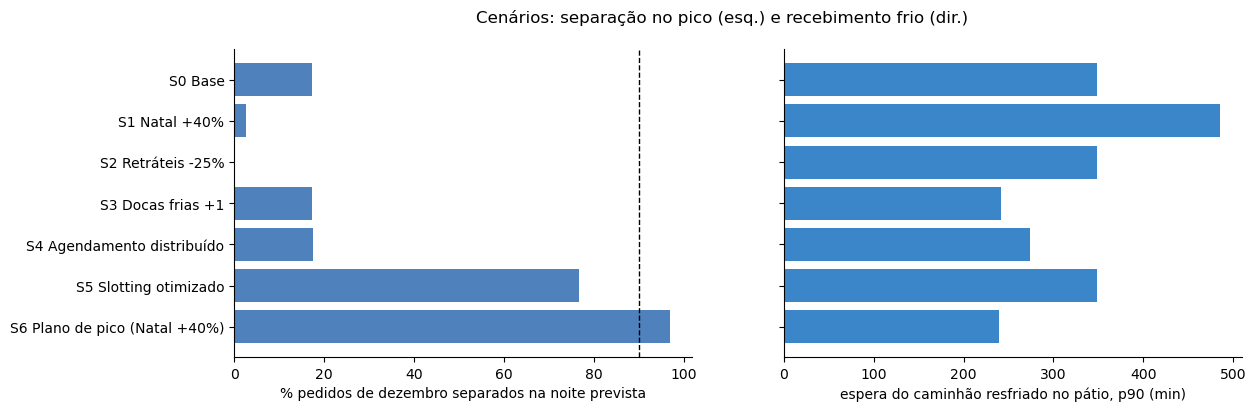

In [6]:
# Barras horizontais: cada cenário é uma categoria com nome longo; compara um único indicador.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ordem = comp.index[::-1]
axes[0].barh(ordem, comp.loc[ordem, "% noite prevista dez"], color="#4F81BD")
axes[0].axvline(90, color="black", ls="--", lw=1); axes[0].set_xlabel("% pedidos de dezembro separados na noite prevista")
axes[1].barh(ordem, comp.loc[ordem, "pátio p90 resfr. (min)"], color="#3A86C8")
axes[1].set_xlabel("espera do caminhão resfriado no pátio, p90 (min)"); axes[1].set_yticklabels([])
fig.suptitle("Cenários: separação no pico (esq.) e recebimento frio (dir.)")
savefig(fig, "06b_cenarios", out=PH6)

## Leitura dos cenários
Os números de cada cenário estão na tabela acima; aqui vai a interpretação para a gestão.

- **S0 Base:** mesmo sem Natal extra, só **17%** dos pedidos de dezembro saem na noite prevista.
  A operação atual já está no limite no pico.
- **S1 Natal +40%:** dezembro colapsa: fila de **~8 dias** em dezembro e de ~13 em janeiro (o atraso
  se acumula). O risco do pico é **capacidade de separação**; o recebimento piora, mas aguenta.
- **S2 Retráteis −25%:** cortar frota derruba a **separação pelo pulmão à noite** mesmo em
  outubro (de 99% para 55% na noite prevista). O recebimento de dia quase não sente. Reduzir frota
  **antes** do slotting é um erro caro.
- **S3 Docas frias +1:** a espera p90 do caminhão resfriado cai de ~5,8 h para ~4 h e a do
  congelado de ~2,8 h para ~1,7 h. A fila de doca é não linear: uma doca a mais numa zona saturada vale muito.
- **S4 Agendamento distribuído:** sem investimento, reduz a espera p90 do resfriado em ~1¼ h e
  corta pela metade a do seco. **É a primeira ação a fazer** e pode adiar a doca extra.
- **S5 Slotting otimizado:** o tempo por pedido cai só ~6%, mas como a separação está no limite, a
  fila responde de forma **não linear**: dezembro vai de **17% para 77%** dos pedidos na noite
  prevista, **sem contratar ninguém**. É o maior retorno de todos os cenários.
- **S6 Plano de pico:** com S3 + S4 + S5, o Natal +40% exige **+50%** na equipe da noite
  (+49 separadores e +20 retráteis) para manter ≥ 90% dos pedidos na noite prevista. **Sem o slotting**
  seriam **+60%** (+59 e +24). O slotting evita ≈ **R$ 287 mil em temporários por temporada**
  (estimativa, escala cheia).

In [7]:
# Custo do reforço de pico (temporários) e da doca extra, para o registro de custos da Fase 10
P = params()
c_sep, c_ret = P["labor_cost"]["picker_brl_h"], P["labor_cost"]["reach_truck_brl_h"]
base_sep, base_ret = sum(prm["pickers"].values()), sum(prm["forklifts_night"].values())
extra_sep = escolhido["separadores"] - base_sep
extra_ret = escolhido["retrateis_noite"] - base_ret
noites_pico = 26 * 3                       # nov-jan, seg-sáb (estimativa)
custo_reforco = (extra_sep * c_sep + extra_ret * c_ret) * prm["shift_hours"] * noites_pico
print(f"Reforço de pico: +{extra_sep} separadores e +{extra_ret} retráteis por noite, "
      f"≈ R$ {custo_reforco:,.0f} na temporada (nov–jan, premissa de custo da hora do config)")

# Sem slotting: reforço necessário e custo; a diferença é o valor do slotting no pico
extra_sep_s = escolhido_sem["separadores"] - base_sep
extra_ret_s = escolhido_sem["retrateis_noite"] - base_ret
custo_sem = (extra_sep_s * c_sep + extra_ret_s * c_ret) * prm["shift_hours"] * noites_pico
atingiu = escolhido_sem["na_noite_prevista_2025-12"] >= 0.90   # se False, o valor é um mínimo
print(f"Sem slotting: +{extra_sep_s} separadores e +{extra_ret_s} retráteis "
      f"({'atinge' if atingiu else 'NÃO atinge'} 90%) ≈ R$ {custo_sem:,.0f}")
print(f"Reforço evitado pelo slotting: ≈ R$ {custo_sem - custo_reforco:,.0f} por temporada de pico"
      + ("" if atingiu else " (mínimo: sem slotting nem o maior reforço testado bastou)"))
register_saving(6, "Slotting otimizado reduz temporários no pico (simulação Natal +40%)",
                "custo do reforço de equipe nov-jan (R$)", round(custo_sem), round(custo_reforco),
                f"separadores +{extra_sep_s} -> +{extra_sep}; retráteis noite +{extra_ret_s} -> +{extra_ret}",
                "config/parameters.yaml labor_cost; 78 noites; escala cheia", custo_sem - custo_reforco, 0)
register_saving(6, "Agendamento distribuído de docas (simulação)", "espera p90 do caminhão resfriado no pátio (min)",
                round(tab.loc["S0 Base", "espera_doca_p90_chilled"]),
                round(tab.loc["S4 Agendamento distribuído", "espera_doca_p90_chilled"]),
                "menos fila de caminhão frio; dock-to-stock menor nas 3 zonas",
                "sem valor em R$ (custo de estadia de caminhão não modelado)", 0, 0)

# Quanto o slotting (S5) reduz o tempo de separação por pedido? (capacidade liberada)
sub_atual = fs.preparar_pedidos("2025-10-01", "2025-11-01", slot, prm, dist_col="dist_face_m")
sub_otimo = fs.preparar_pedidos("2025-10-01", "2025-11-01", slot, prm, dist_col="dist_otima")
h_atual = (sub_atual.picker_s + sub_atual.retratil_s).sum() / 3600
h_otimo = (sub_otimo.picker_s + sub_otimo.retratil_s).sum() / 3600
print(f"Slotting otimizado: horas de separação + retrátil por pedido −{100 * (1 - h_otimo / h_atual):.1f}%")
log(NB, "cenários S0–S6 em escala cheia (bootstrap x10), janela set/2025–jan/2026, medição a partir de out/2025")

Reforço de pico: +49 separadores e +20 retráteis por noite, ≈ R$ 1,417,728 na temporada (nov–jan, premissa de custo da hora do config)
Sem slotting: +59 separadores e +24 retráteis (atinge 90%) ≈ R$ 1,704,768
Reforço evitado pelo slotting: ≈ R$ 287,040 por temporada de pico


Slotting otimizado: horas de separação + retrátil por pedido −6.4%


## Plano de ação (5W2H)
| O quê | Por quê | Quem | Quando | Como | Quanto |
|---|---|---|---|---|---|
| Agendamento distribuído de docas | Fila de caminhão frio no pátio; pico 7–12h | Coord. recebimento | Imediato | Janelas por fornecedor; tarde para secos | Zero |
| Slotting otimizado (Fase 5) antes do pico | Libera capacidade de separação e retrátil | Armazenagem | Até out/2026 | Plano de transição da 05b | ≈ 38 h de retrátil |
| +1 doca fria em cada câmara (se o agendamento não bastar) | Doca fria é o gargalo do recebimento | Engenharia | Avaliar após 3 meses de agendamento | Projeto de doca com antecâmara | A orçar (Fase 8) |
| Reforço de equipe para o Natal | +40% de demanda colapsa a separação | RH + Operações | Contratar em out/2026 | Temporários nos níveis da tabela de reforço | Ver cálculo acima |
| Não reduzir frota de retráteis antes do slotting | S2 mostra impacto direto na separação noturna | Operações | — | Rever após implantar S5 | — |